# 18 — exp2 against exp1 at 2° (20 kt) and 180° (60 kt)

The same slice of the requirement from both campaigns: exp1 (six variables, 250 samples over all headings and speeds) read at 2°/20 kt and 180°/60 kt, and exp2 (four variables, 250 samples at each). Prediction of each surrogate model, no new simulations.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from mvlse import fit_surrogate

sys.path.insert(0, str(Path.cwd().parent))
import config

RES = Path.cwd().parent / "results"
TAU = config.TAU


def load(store, space):
    rows = [json.loads(l) for l in store.read_text().splitlines() if l.strip()]
    w = space.encode([r["point"] for r in rows])
    y = np.array([r["y"] for r in rows])
    m = fit_surrogate(config.LSE["method"], space, w, y, correlation=config.LSE["correlation"],
                      rng=np.random.default_rng(config.SEED), n_starts=12)
    return rows, w, y, m


space1 = config.space_of(config.EXPERIMENTS["exp1_heading"]["space"])
space2 = config.space_of(config.EXPERIMENTS["exp2_surface"]["space"])
rows1, w1, y1, m1 = load(RES / "exp1_heading" / "campaign" / "store.jsonl", space1)
EXP2 = {d: load(RES / "exp2_surface" / f"dpsi{d}_campaign" / "store.jsonl", space2) for d in (2, 180)}
print(f"exp1: {len(y1)} samples (all headings and speeds); exp2: " +
      ", ".join(f"{d} deg {len(v[2])} samples" for d, v in EXP2.items()))

exp1: 250 samples (all headings and speeds); exp2: 2 deg 250 samples, 180 deg 250 samples


In [2]:
def compare(dpsi, speed_kt):
    rows2, w2, y2, m2 = EXP2[dpsi]
    psi_u, spd_i = (0.0, 0) if dpsi == 2 else (1.0, 2)
    # The same slice from both, at one heading and speed class: every (position, velocity) category, on the
    # reception-range plane. exp1 is read at that edge of its heading range and that speed level.
    N = 61
    gp_, gr_ = np.meshgrid(np.linspace(0, 1, N), np.linspace(0, 1, N), indexing="ij")
    base = np.column_stack([gp_.ravel(), gr_.ravel()])
    P_ = space2.variable("p_reception").from_unit(gp_)
    R_ = space2.variable("max_range_m").from_unit(gr_) / 1e3
    pos_levels, vel_levels = space2.variable("pos_ci95").levels, space2.variable("vel_ci95").levels
    FOUR = ListedColormap(["tab:red", "tab:orange", "tab:blue", "tab:green"])
    assert space1.continuous_names == ("p_reception", "max_range_m", "dpsi")
    assert space1.discrete_names == ("pos_ci95", "vel_ci95", "speed") and space2.discrete_names == ("pos_ci95", "vel_ci95")

    fig, axes = plt.subplots(len(vel_levels), len(pos_levels), figsize=(15, 10.5), sharex=True, sharey=True)
    rows = []
    for j, vel in enumerate(vel_levels):
        for i, pos in enumerate(pos_levels):
            ax = axes[j, i]
            mu1 = m1.predict(np.column_stack([base, np.full(len(base), psi_u), np.full(len(base), i),
                                              np.full(len(base), j), np.full(len(base), spd_i)]))[0].reshape(N, N)
            mu2 = m2.predict(np.column_stack([base, np.full(len(base), i), np.full(len(base), j)]))[0].reshape(N, N)
            a1, a2 = mu1 <= TAU, mu2 <= TAU
            code = np.where(a1 & a2, 3, np.where(~a1 & ~a2, 0, np.where(a1, 1, 2)))
            ax.pcolormesh(P_, R_, code, cmap=FOUR, vmin=-0.5, vmax=3.5, shading="auto")
            ax.contour(P_, R_, mu1, levels=[TAU], colors="white", linewidths=1.5, linestyles="dashed")
            ax.contour(P_, R_, mu2, levels=[TAU], colors="black", linewidths=1.8, linestyles="solid")
            s = (w2[:, 2] == i) & (w2[:, 3] == j)
            pts = np.array([[r["point"]["p_reception"], r["point"]["max_range_m"] / 1e3] for r in rows2])[s]
            ax.scatter(pts[:, 0], pts[:, 1], s=14, c=np.where(y2[s] <= TAU, "white", "black"), edgecolors="black",
                       linewidths=0.6, zorder=3)
            rows.append({"velocity [m/s]": vel, "position [m]": pos, "exp1 acceptable": a1.mean(),
                         "exp2 acceptable": a2.mean(), "agree": (a1 == a2).mean(), "exp2 samples": int(s.sum())})
            ax.set_title(f"velocity {vel:g} m/s, position {pos:g} m:  {a1.mean():.2f} -> {a2.mean():.2f}", fontsize=9)
            if j == len(vel_levels) - 1: ax.set_xlabel("reception probability")
            if i == 0: ax.set_ylabel("surveillance range [km]")
    fig.suptitle(f"{speed_kt} kt, relative heading {dpsi} deg. Green: acceptable in both; red: in neither; orange: acceptable only in exp1; "
                 f"blue: only in exp2.\nWhite dashed: exp1 boundary (250 samples over all headings and speeds); black: exp2 "
                 f"boundary (250 samples at this heading and speed). Dots: exp2 samples (white acceptable, black not).",
                 x=0.01, ha="left", fontsize=9)
    plt.tight_layout(rect=(0, 0, 1, 0.94)); plt.savefig(f"results/exp1_vs_exp2_{dpsi}deg.png", dpi=130); plt.show()
    return pd.DataFrame(rows).round(2)

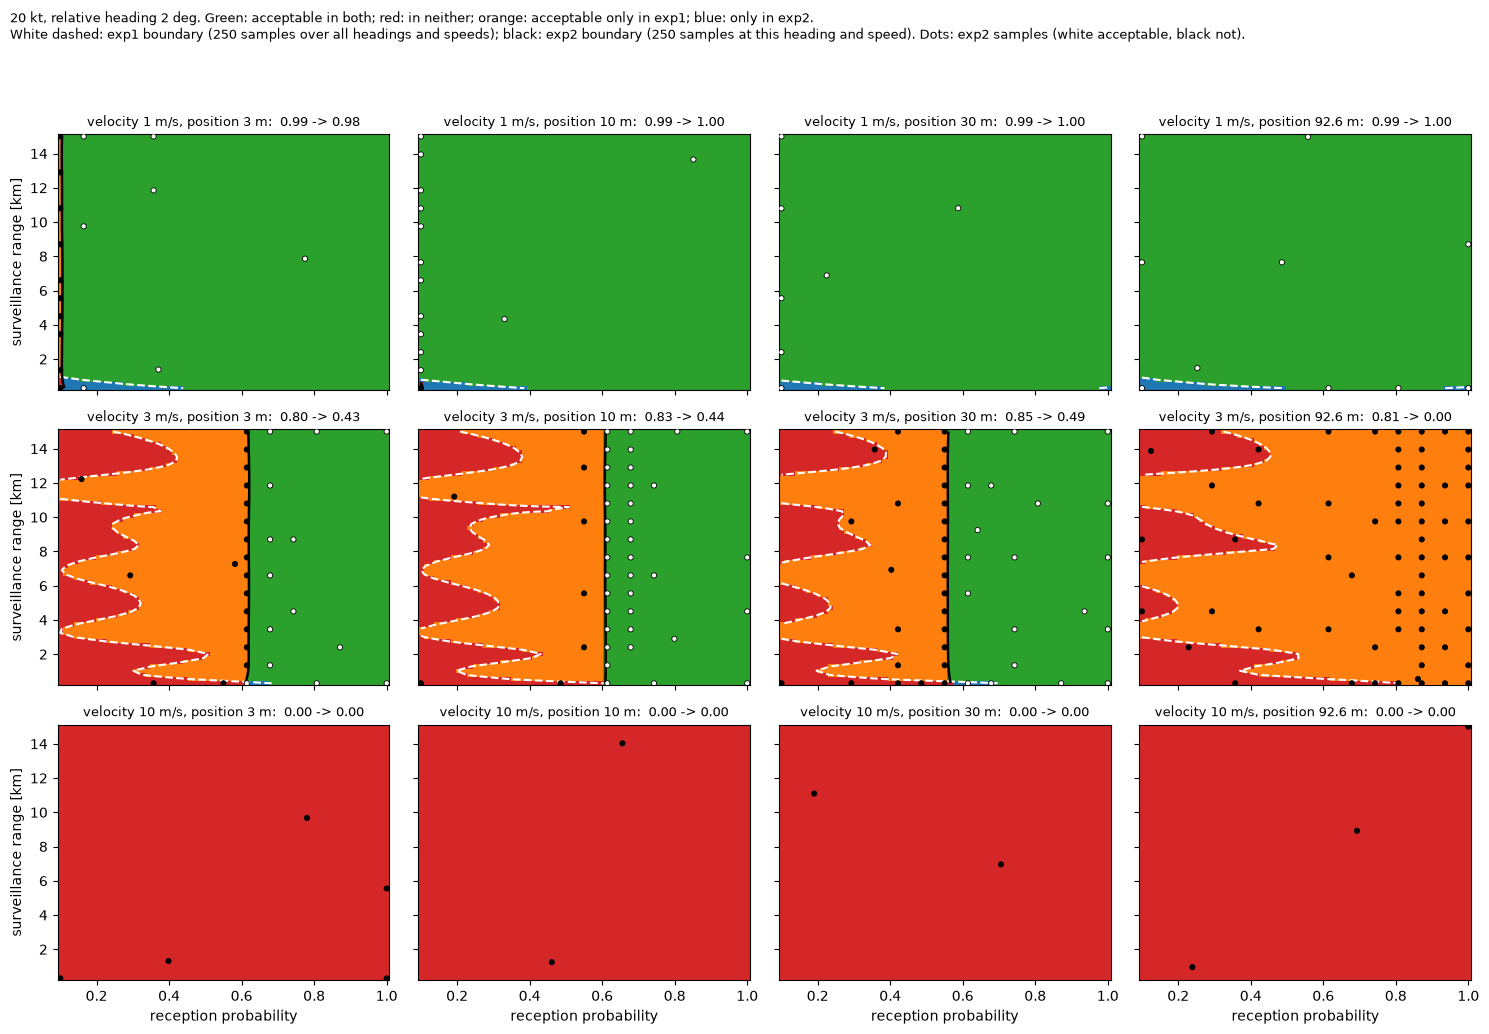

,velocity [m/s],position [m],exp1 acceptable,exp2 acceptable,agree,exp2 samples
0,1.0,3.0,0.99,0.98,0.97,17
1,1.0,10.0,0.99,1.00,0.99,14
2,1.0,30.0,0.99,1.00,0.99,7
3,1.0,92.6,0.99,1.00,0.99,10
4,3.0,3.0,0.80,0.43,0.62,33
5,3.0,10.0,0.83,0.44,0.62,45
6,3.0,30.0,0.85,0.49,0.64,46
7,3.0,92.6,0.81,0.00,0.19,66
8,10.0,3.0,0.00,0.00,1.00,5
9,10.0,10.0,0.00,0.00,1.00,2


In [3]:
compare(2, 20)

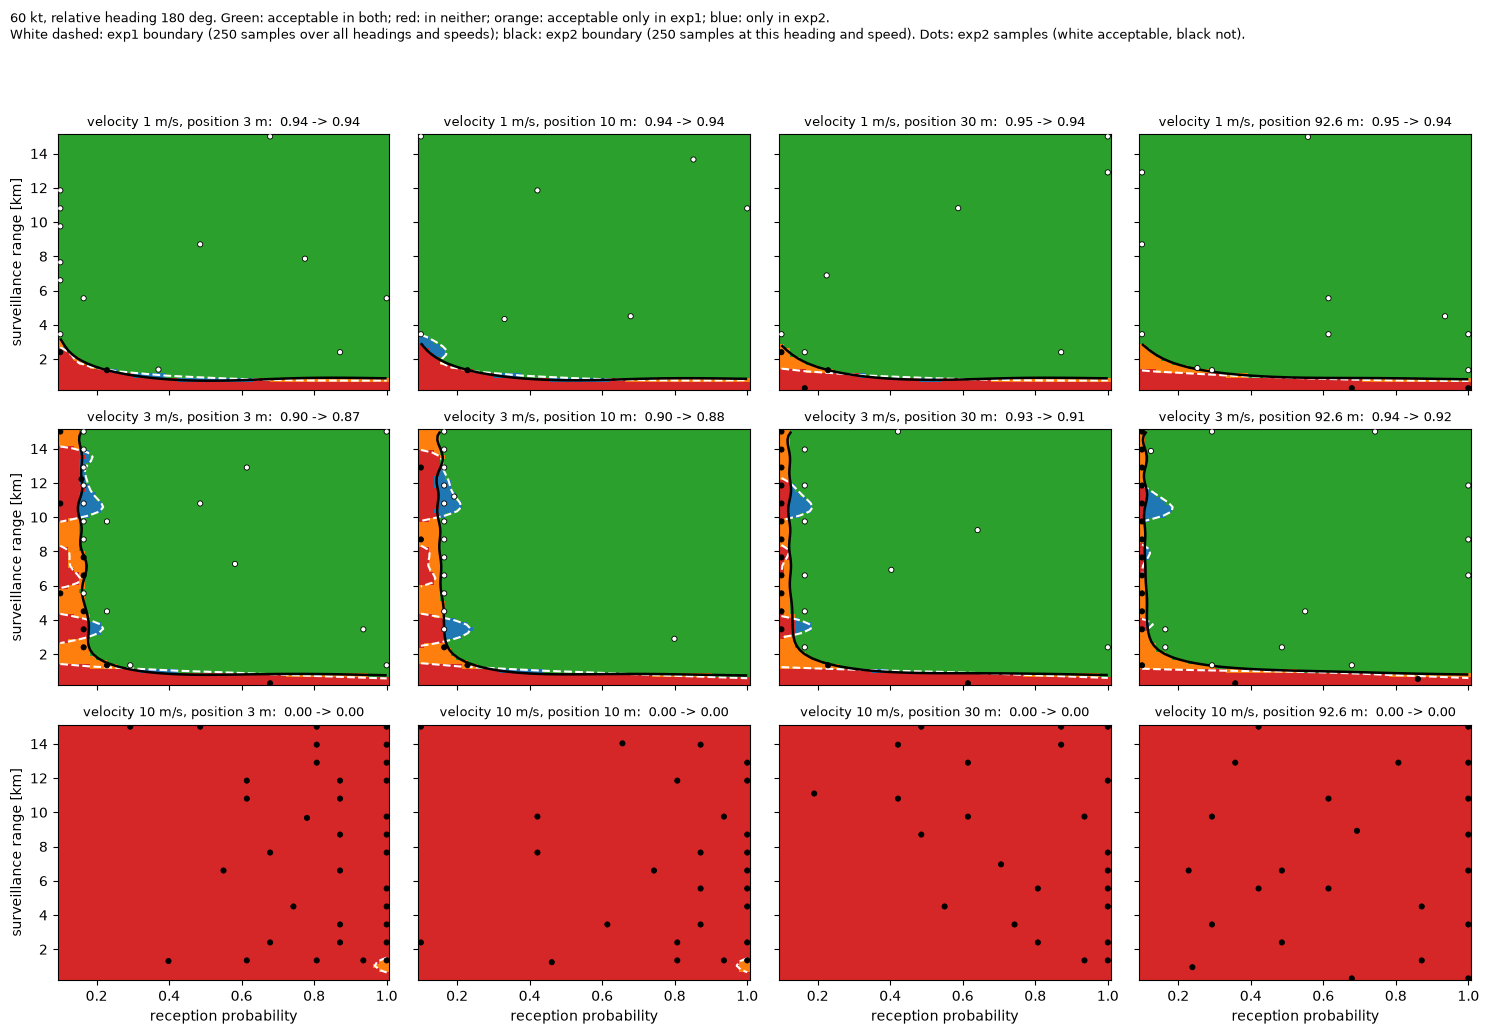

,velocity [m/s],position [m],exp1 acceptable,exp2 acceptable,agree,exp2 samples
0,1.0,3.0,0.94,0.94,0.99,15
1,1.0,10.0,0.94,0.94,0.99,8
2,1.0,30.0,0.95,0.94,0.99,10
3,1.0,92.6,0.95,0.94,0.98,13
4,3.0,3.0,0.90,0.87,0.95,28
5,3.0,10.0,0.90,0.88,0.95,18
6,3.0,30.0,0.93,0.91,0.96,24
7,3.0,92.6,0.94,0.92,0.96,27
8,10.0,3.0,0.00,0.00,1.00,34
9,10.0,10.0,0.00,0.00,1.00,26


In [4]:
compare(180, 60)

## Insight

**1. The two regimes set different requirements.**
- **2°, 20 kt (shallow):** the requirement is a reception floor, and range does not matter. At 3 m/s, reception probability of about 0.62 (3 and 10 m position accuracy) or 0.56 (30 m), and no reception is enough at 92.6 m.
- **180°, 60 kt (head-on):** the requirement is mainly a range floor of about 1 km, rising to about 3 km at low reception. At 3 m/s there is also a reception floor of only about 0.15–0.2. Position accuracy has no effect here.

The CNS requirement is the union of the two: the reception floor comes from the shallow regime, the range floor from the head-on regime. At 10 m/s nothing is acceptable in either.

**2. exp1 got the head-on regime right and the shallow regime wrong.**
- **180°:** exp1 and exp2 classify 95–99% of the plane alike, and the acceptable shares differ by at most 0.03.
- **2°:** at 3 m/s, exp1 was too lenient by about half the plane, and by all of it at 92.6 m.

**3. This fits the squeezed heading scale.** Closing speed, 2V sin(ψ/2), is nearly flat around 180° and changes fastest near 2°. With one correlation-function hyperparameter for the heading, exp1 could follow the flat end and smoothed the steep one. Both are edges of the heading range, so the edge alone does not explain the difference; the steepness does.

**4. Where exp2 spent its samples.**
- **2°:** most samples went along the reception floor at 3 m/s.
- **180°:** more than a third (107 of 250) went to the 10 m/s categories. Those categories are unacceptable everywhere, but not by much: the median of those samples is $P(\mathrm{LoS}) = 4.8\times10^{-3}$, about five times the threshold. The straddle kept checking whether some reception and range would bring them below $10^{-3}$. None did, so at head-on 10 m/s fails narrowly, not by orders of magnitude as at 2°.